In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, LeaveOneOut, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from scipy.stats import randint

RANDOM_STATE = 42
DATA_PATH = Path("Water Quality.csv")
TARGET_NAME = "Specific conductance"

In [2]:
if not DATA_PATH.exists():
    csvs = list(Path.cwd().glob("*.csv"))
    if len(csvs) == 1:
        DATA_PATH = csvs[0]
        print("Using:", DATA_PATH)
    else:
        raise FileNotFoundError("Put Water Quality.csv beside this notebook or update DATA_PATH.")

raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Raw shape:", raw.shape)
display(raw.head())
required = {"CharacteristicName", "ResultValue"}
if not required.issubset(raw.columns):
    raise ValueError(f"Missing expected columns: {required - set(raw.columns)}")

df = raw.copy()
df["CharacteristicName"] = df["CharacteristicName"].astype(str).str.strip()
df["ResultValue"] = pd.to_numeric(df["ResultValue"], errors="coerce")
keys = [c for c in ["MonitoringLocationID", "ActivityStartDate"] if c in df.columns]
if not keys:
    raise ValueError("Expected MonitoringLocationID and/or ActivityStartDate as sample keys.")
if "ActivityStartDate" in df:
    df["ActivityStartDate"] = pd.to_datetime(df["ActivityStartDate"], errors="coerce")
    df = df.dropna(subset=["ActivityStartDate"])
df = df.dropna(subset=["ResultValue"])
wide = df.pivot_table(index=keys, columns="CharacteristicName", values="ResultValue", aggfunc="mean").reset_index()
wide.columns.name = None
print("Pivoted shape:", wide.shape)
display(wide.head())

Raw shape: (229916, 40)


,DatasetName,MonitoringLocationID,MonitoringLocationName,MonitoringLocationLatitude,MonitoringLocationLongitude,MonitoringLocationHorizontalCoordinateReferenceSystem,MonitoringLocationHorizontalAccuracyMeasure,MonitoringLocationHorizontalAccuracyUnit,MonitoringLocationVerticalMeasure,MonitoringLocationVerticalUnit,...,ResultStatusID,ResultComment,ResultAnalyticalMethodID,ResultAnalyticalMethodContext,ResultAnalyticalMethodName,AnalysisStartDate,AnalysisStartTime,AnalysisStartTimeZone,LaboratoryName,LaboratorySampleID
0,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,110688,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
1,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,2011,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
2,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,20110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
3,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,17209,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
4,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,...,Preliminary,NaN,10110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN


Pivoted shape: (7283, 85)


,MonitoringLocationID,ActivityStartDate,"Alkalinity, total",Aluminum,Ammonia,Antimony,Apparent color,Arsenic,Barium,Beryllium,...,True color,Tungsten,Turbidity,Uranium,Vanadium,Ytterbium,Yttrium,Zinc,Zirconium,pH
0,NB01BR0006,2000-09-22,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NB01BR0006,2000-10-11,NaN,NaN,NaN,NaN,274.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NB01BR0006,2000-11-23,NaN,NaN,NaN,NaN,215.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NB01BR0006,2001-04-26,1.8,NaN,NaN,NaN,158.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.9
4,NB01BR0006,2001-05-22,2.8,NaN,NaN,NaN,315.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.1


In [3]:
matches = [c for c in wide.columns if TARGET_NAME.casefold() in str(c).casefold()]
if not matches:
    raise ValueError(f"Target {TARGET_NAME!r} not found. Available measurements: {[c for c in wide.columns if c not in keys][:40]}")
target_col = matches[0]
exclude_terms = ("conductivity", "specific conductance")
features = [c for c in wide.columns if c not in keys and c != target_col
            and not any(t in str(c).casefold() for t in exclude_terms)
            and pd.api.types.is_numeric_dtype(wide[c])]
data = wide[[*keys, target_col, *features]].replace([np.inf, -np.inf], np.nan).dropna(subset=[target_col])
features = [c for c in features if data[c].notna().any() and data[c].nunique(dropna=True) > 1]
if not features:
    raise ValueError("No usable predictor columns after removing target leakage candidates.")
X = data[features].copy()
y = pd.to_numeric(data[target_col], errors="coerce")
valid = y.notna()
X, y, data = X.loc[valid], y.loc[valid], data.loc[valid]

if "ActivityStartDate" in data:
    idx = data["ActivityStartDate"].sort_values().index
    cut = int(0.8 * len(idx))
    train_idx, test_idx = idx[:cut], idx[cut:]
    if not len(train_idx) or not len(test_idx):
        train_idx, test_idx = train_test_split(data.index, test_size=.2, random_state=RANDOM_STATE)
else:
    train_idx, test_idx = train_test_split(data.index, test_size=.2, random_state=RANDOM_STATE)

X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
print("Target:", target_col, "| X train:", X_train.shape, "| X test:", X_test.shape)

Target: Specific conductance | X train: (5777, 79) | X test: (1445, 79)


In [4]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", ExtraTreesRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
test_pred = model.predict(X_test)
point = {"MAE": mean_absolute_error(y_test, test_pred),
         "RMSE": mean_squared_error(y_test, test_pred)**0.5,
         "R2": r2_score(y_test, test_pred)}
print("Held-out test metrics:", point)

rng = np.random.default_rng(RANDOM_STATE)
yt, yp = np.asarray(y_test), np.asarray(test_pred)
maes, rmses, r2s = [], [], []
for _ in range(1000):
    ix = rng.integers(0, len(yt), len(yt))
    a, b = yt[ix], yp[ix]
    maes.append(mean_absolute_error(a, b))
    rmses.append(mean_squared_error(a, b)**0.5)
    if np.std(a) > 0:
        r2s.append(r2_score(a, b))
boot_rows = []
for name, vals in [("MAE", maes), ("RMSE", rmses), ("R2", r2s)]:
    lo, hi = np.percentile(vals, [2.5, 97.5])
    boot_rows.append({"Metric": name, "Point estimate": point[name], "95% CI lower": lo, "95% CI upper": hi})
bootstrap_table = pd.DataFrame(boot_rows)
display(bootstrap_table.round(4))
bootstrap_table.to_csv("task5_bootstrap_uncertainty.csv", index=False)

Held-out test metrics: {'MAE': 9.001400478662047, 'RMSE': 42.47087051870191, 'R2': 0.9303663369027018}


,Metric,Point estimate,95% CI lower,95% CI upper
0,MAE,9.0014,6.9142,11.1294
1,RMSE,42.4709,26.5970,57.4949
2,R2,0.9304,0.8743,0.9697


,Feature,Importance mean (MAE increase),Importance std
15,Chloride,38.56763,0.69243
57,Sodium,24.12828,0.56581
12,Calcium,15.30736,0.37894
0,"Alkalinity, total",8.18524,0.28523
59,Sulfate,3.75812,0.13759
28,Gran acid neutralizing capacity,3.32843,0.11591
78,pH,3.18867,0.15458
38,Magnesium,3.01058,0.08028
58,Strontium,2.02189,0.06261
67,"Total Nitrogen, mixed forms",0.39655,0.01832


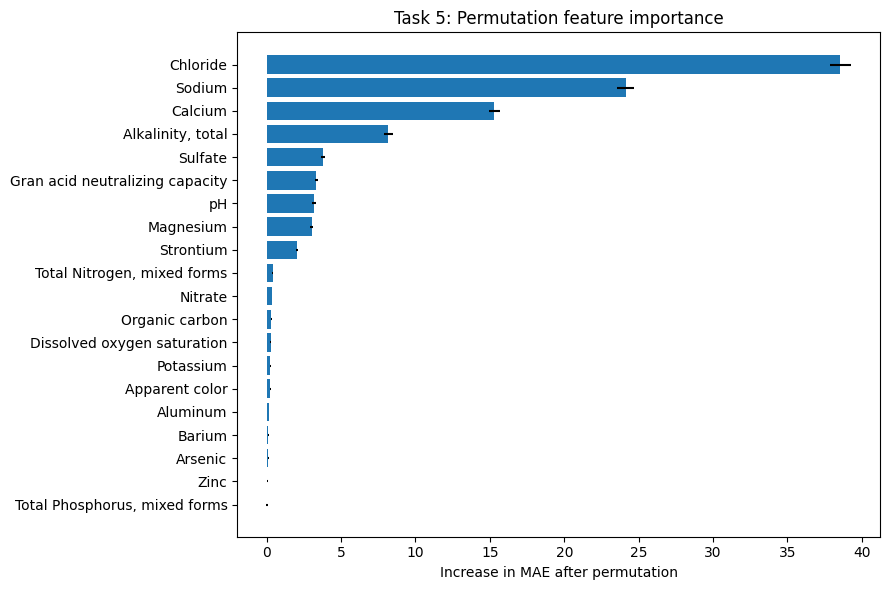

In [5]:
perm = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
                              scoring="neg_mean_absolute_error", n_jobs=-1)
perm_table = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance mean (MAE increase)": perm.importances_mean,
    "Importance std": perm.importances_std
}).sort_values("Importance mean (MAE increase)", ascending=False)
display(perm_table.head(20).round(5))
perm_table.to_csv("task5_permutation_feature_importance.csv", index=False)

top = perm_table.head(20).sort_values("Importance mean (MAE increase)")
plt.figure(figsize=(9, max(5, len(top)*0.3)))
plt.barh(top["Feature"].astype(str), top["Importance mean (MAE increase)"], xerr=top["Importance std"])
plt.xlabel("Increase in MAE after permutation")
plt.title("Task 5: Permutation feature importance")
plt.tight_layout()
plt.show()